Number of experts: 10
Occupancy shape: (10, 400)
Expert types:
  Expert 1: good
  Expert 2: good
  Expert 3: good
  Expert 4: good
  Expert 5: good
  Expert 6: noisy
  Expert 7: noisy
  Expert 8: noisy
  Expert 9: corrupted
  Expert 10: corrupted


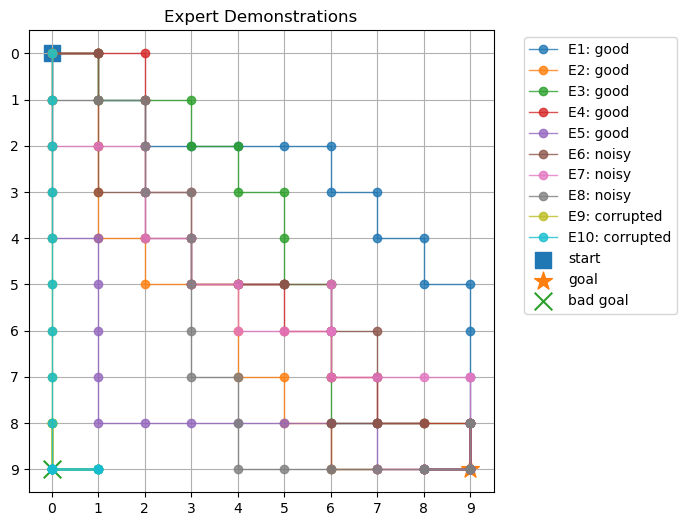

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Cell 1: GridWorld + expert demonstrations + occupancies
# ============================================================

np.random.seed(7)

# -----------------------------
# Environment
# -----------------------------
H, W = 10, 10
n_states = H * W
actions = ["up", "down", "left", "right"]
n_actions = len(actions)

start = (0, 0)
goal = (9, 9)
bad_goal = (9, 0)

T = 25
gamma = 0.95

def state_id(s):
    return s[0] * W + s[1]

def step(s, a):
    r, c = s

    if a == 0:      # up
        r = max(r - 1, 0)
    elif a == 1:    # down
        r = min(r + 1, H - 1)
    elif a == 2:    # left
        c = max(c - 1, 0)
    elif a == 3:    # right
        c = min(c + 1, W - 1)

    return (r, c)

def greedy_action_toward(s, target):
    r, c = s
    tr, tc = target

    candidates = []

    if tr > r:
        candidates.append(1)  # down
    if tr < r:
        candidates.append(0)  # up
    if tc > c:
        candidates.append(3)  # right
    if tc < c:
        candidates.append(2)  # left

    if len(candidates) == 0:
        return np.random.choice(n_actions)

    return np.random.choice(candidates)

# -----------------------------
# Expert trajectory generator
# -----------------------------
def generate_trajectory(expert_type, noise_prob=0.0):
    """
    expert_type:
        'good'      : moves toward the true goal
        'noisy'     : mostly good, but random actions sometimes
        'corrupted' : moves toward the wrong goal
    """
    s = start
    traj = []

    for t in range(T):
        if expert_type == "good":
            a = greedy_action_toward(s, goal)

        elif expert_type == "noisy":
            if np.random.rand() < noise_prob:
                a = np.random.choice(n_actions)
            else:
                a = greedy_action_toward(s, goal)

        elif expert_type == "corrupted":
            a = greedy_action_toward(s, bad_goal)

        else:
            raise ValueError("Unknown expert type.")

        traj.append((s, a))
        s = step(s, a)

    return traj

# -----------------------------
# Create multiple experts
# -----------------------------
E = 10
N_per_expert = 20

expert_types = (
    ["good"] * 5
    + ["noisy"] * 3
    + ["corrupted"] * 2
)

expert_trajectories = []

for e in range(E):
    etype = expert_types[e]

    if etype == "good":
        demos = [generate_trajectory("good", noise_prob=0.0)
                 for _ in range(N_per_expert)]

    elif etype == "noisy":
        demos = [generate_trajectory("noisy", noise_prob=0.25)
                 for _ in range(N_per_expert)]

    elif etype == "corrupted":
        demos = [generate_trajectory("corrupted", noise_prob=0.0)
                 for _ in range(N_per_expert)]

    expert_trajectories.append(demos)

# -----------------------------
# Empirical occupancy measure
# over state-action pairs
# -----------------------------
def empirical_occupancy(trajectories):
    rho = np.zeros(n_states * n_actions)

    for traj in trajectories:
        for t, (s, a) in enumerate(traj):
            idx = state_id(s) * n_actions + a
            rho[idx] += gamma ** t

    rho = rho / len(trajectories)

    # normalize for easier comparison
    rho = rho / (rho.sum() + 1e-12)

    return rho

rho_hat = np.array([
    empirical_occupancy(expert_trajectories[e])
    for e in range(E)
])

print("Number of experts:", E)
print("Occupancy shape:", rho_hat.shape)
print("Expert types:")
for e, etype in enumerate(expert_types):
    print(f"  Expert {e+1}: {etype}")

# -----------------------------
# Simple visualization
# -----------------------------
def plot_one_trajectory(traj, label=None):
    xs = [s[1] for s, a in traj]
    ys = [s[0] for s, a in traj]
    plt.plot(xs, ys, marker="o", linewidth=1, alpha=0.8, label=label)

plt.figure(figsize=(6, 6))

for e in range(E):
    traj = expert_trajectories[e][0]
    plot_one_trajectory(traj, label=f"E{e+1}: {expert_types[e]}")

plt.scatter(start[1], start[0], marker="s", s=120, label="start")
plt.scatter(goal[1], goal[0], marker="*", s=180, label="goal")
plt.scatter(bad_goal[1], bad_goal[0], marker="x", s=160, label="bad goal")

plt.xlim(-0.5, W - 0.5)
plt.ylim(H - 0.5, -0.5)
plt.xticks(range(W))
plt.yticks(range(H))
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.title("Expert Demonstrations")
plt.show()

Optimization success: True
alpha_pi: 1.0
Support experts: [ 1  3  4  6  8  9 10]

Expert  1 | type = good      | alpha = 1.0000
Expert  2 | type = good      | alpha = 0.0000
Expert  3 | type = good      | alpha = 1.0000
Expert  4 | type = good      | alpha = 0.8994
Expert  5 | type = good      | alpha = 0.0000
Expert  6 | type = noisy     | alpha = 1.0000
Expert  7 | type = noisy     | alpha = 0.0000
Expert  8 | type = noisy     | alpha = 1.0000
Expert  9 | type = corrupted | alpha = 1.0000
Expert 10 | type = corrupted | alpha = 0.3820


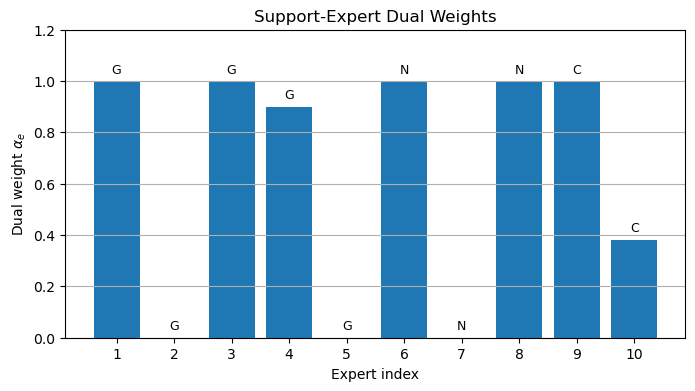

In [9]:
# ============================================================
# Cell 2: RKHS kernel embeddings + support-expert dual
# ============================================================

from scipy.optimize import minimize

# -----------------------------
# State-action feature vectors
# -----------------------------
def state_action_features():
    X = []

    for s_idx in range(n_states):
        r = s_idx // W
        c = s_idx % W

        for a in range(n_actions):
            # normalized row, column, and action index
            X.append([r / (H - 1), c / (W - 1), a / (n_actions - 1)])

    return np.array(X)

X_sa = state_action_features()

def rbf_kernel(X, sigma=0.35):
    sqdist = np.sum((X[:, None, :] - X[None, :, :]) ** 2, axis=-1)
    return np.exp(-sqdist / (2 * sigma ** 2))

K_sa = rbf_kernel(X_sa, sigma=0.35)

# -----------------------------
# RKHS inner product between occupancy embeddings
# <mu_i, mu_j> = rho_i^T K rho_j
# -----------------------------
def embedding_inner_product(rho1, rho2):
    return rho1 @ K_sa @ rho2

G_expert = rho_hat @ K_sa @ rho_hat.T

# -----------------------------
# Initial learner policy: random
# -----------------------------
def generate_random_policy_trajectory():
    s = start
    traj = []

    for t in range(T):
        a = np.random.choice(n_actions)
        traj.append((s, a))
        s = step(s, a)

    return traj

N_pi = 40
learner_trajectories = [
    generate_random_policy_trajectory()
    for _ in range(N_pi)
]

rho_pi = empirical_occupancy(learner_trajectories)

g_expert_pi = np.array([
    embedding_inner_product(rho_hat[e], rho_pi)
    for e in range(E)
])

g_pi_pi = embedding_inner_product(rho_pi, rho_pi)

# -----------------------------
# Solve support-expert dual
#
# max_alpha sum_e alpha_e + alpha_pi
#           - 1/2 || sum_e alpha_e mu_e - alpha_pi mu_pi ||^2
#
# subject to 0 <= alpha_e <= C
#            0 <= alpha_pi <= C_pi
# -----------------------------
C = 1.0
C_pi = 1.0

def dual_objective(x):
    alpha = x[:E]
    alpha_pi = x[E]

    norm_sq = (
        alpha @ G_expert @ alpha
        - 2 * alpha_pi * (alpha @ g_expert_pi)
        + alpha_pi ** 2 * g_pi_pi
    )

    value = np.sum(alpha) + alpha_pi - 0.5 * norm_sq

    # scipy minimizes, so return negative
    return -value

bounds = [(0, C)] * E + [(0, C_pi)]

x0 = np.ones(E + 1) * 0.1

result = minimize(
    dual_objective,
    x0,
    method="L-BFGS-B",
    bounds=bounds
)

x_star = result.x
alpha_star = x_star[:E]
alpha_pi_star = x_star[E]

tau_alpha = 1e-3
support_experts = np.where(alpha_star > tau_alpha)[0]

print("Optimization success:", result.success)
print("alpha_pi:", alpha_pi_star)
print("Support experts:", support_experts + 1)
print()

for e in range(E):
    print(
        f"Expert {e+1:2d} | type = {expert_types[e]:9s} | "
        f"alpha = {alpha_star[e]:.4f}"
    )

# -----------------------------
# Plot dual weights
# -----------------------------
plt.figure(figsize=(8, 4))

plt.bar(np.arange(1, E + 1), alpha_star)
plt.xticks(np.arange(1, E + 1))
plt.xlabel("Expert index")
plt.ylabel(r"Dual weight $\alpha_e$")
plt.title("Support-Expert Dual Weights")

for e, etype in enumerate(expert_types):
    plt.text(e + 1, alpha_star[e] + 0.02, etype[0].upper(),
             ha="center", va="bottom", fontsize=9)

plt.ylim(0, max(alpha_star) + 0.2)
plt.grid(True, axis="y")
plt.show()

Robust optimization success: True
beta: 1.0
Support experts robust: [7 9]

Expert  1 | type = good      | epsilon = 0.020 | alpha_nominal = 1.0000 | alpha_robust = 0.0000
Expert  2 | type = good      | epsilon = 0.020 | alpha_nominal = 0.0000 | alpha_robust = 0.0000
Expert  3 | type = good      | epsilon = 0.020 | alpha_nominal = 1.0000 | alpha_robust = 0.0000
Expert  4 | type = good      | epsilon = 0.020 | alpha_nominal = 0.8994 | alpha_robust = 0.0000
Expert  5 | type = good      | epsilon = 0.020 | alpha_nominal = 0.0000 | alpha_robust = 0.0000
Expert  6 | type = noisy     | epsilon = 0.080 | alpha_nominal = 1.0000 | alpha_robust = 0.0000
Expert  7 | type = noisy     | epsilon = 0.080 | alpha_nominal = 0.0000 | alpha_robust = 0.8075
Expert  8 | type = noisy     | epsilon = 0.080 | alpha_nominal = 1.0000 | alpha_robust = 0.0000
Expert  9 | type = corrupted | epsilon = 0.200 | alpha_nominal = 1.0000 | alpha_robust = 0.1925
Expert 10 | type = corrupted | epsilon = 0.200 | alpha_nomina

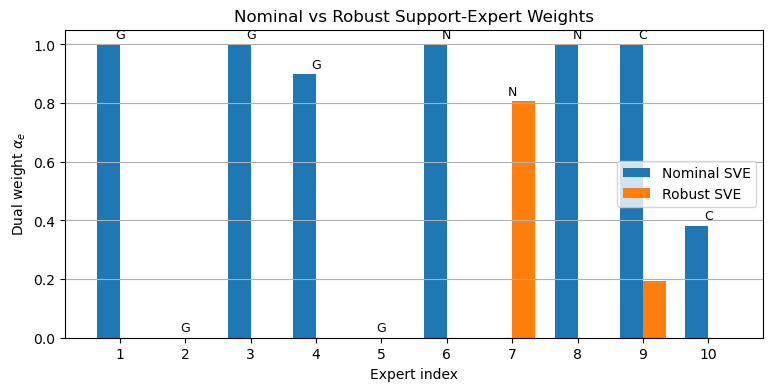


Normalized robust support-expert weights:
Expert  7 | type = noisy     | theta = 0.8075
Expert  9 | type = corrupted | theta = 0.1925


In [10]:
# ============================================================
# Cell 3: Robust support-expert dual with Wasserstein radii
# ============================================================

# Larger epsilon means less reliable expert
epsilon_e = np.zeros(E)

for e, etype in enumerate(expert_types):
    if etype == "good":
        epsilon_e[e] = 0.02
    elif etype == "noisy":
        epsilon_e[e] = 0.08
    elif etype == "corrupted":
        epsilon_e[e] = 0.20

epsilon_pi = 0.02

C_E = 1.0
C_pi = 1.0

# ------------------------------------------------------------
# Robust dual from the paper:
#
# max_alpha,beta  sum_e alpha_e + beta
#   - 1/2 [ || sum_e alpha_e mu_e - beta mu_pi ||_H
#           - (sum_e alpha_e epsilon_e + beta epsilon_pi) ]_+^2
#
# s.t. 0 <= alpha_e <= C_E
#      0 <= beta <= C_pi
#      beta = sum_e alpha_e
# ------------------------------------------------------------

def robust_dual_objective(x):
    alpha = x[:E]
    beta = x[E]

    norm_sq = (
        alpha @ G_expert @ alpha
        - 2 * beta * (alpha @ g_expert_pi)
        + beta ** 2 * g_pi_pi
    )

    norm_val = np.sqrt(max(norm_sq, 0.0))

    shrinkage = alpha @ epsilon_e + beta * epsilon_pi

    robust_margin = max(norm_val - shrinkage, 0.0)

    value = np.sum(alpha) + beta - 0.5 * robust_margin ** 2

    return -value

bounds_robust = [(0, C_E)] * E + [(0, C_pi)]

constraints = [
    {
        "type": "eq",
        "fun": lambda x: x[E] - np.sum(x[:E])
    }
]

# Start from small feasible point
x0 = np.zeros(E + 1)
x0[:E] = 0.05 / E
x0[E] = np.sum(x0[:E])

result_robust = minimize(
    robust_dual_objective,
    x0,
    method="SLSQP",
    bounds=bounds_robust,
    constraints=constraints,
    options={"maxiter": 1000, "ftol": 1e-9}
)

x_robust = result_robust.x
alpha_robust = x_robust[:E]
beta_robust = x_robust[E]

support_experts_robust = np.where(alpha_robust > tau_alpha)[0]

print("Robust optimization success:", result_robust.success)
print("beta:", beta_robust)
print("Support experts robust:", support_experts_robust + 1)
print()

for e in range(E):
    print(
        f"Expert {e+1:2d} | type = {expert_types[e]:9s} | "
        f"epsilon = {epsilon_e[e]:.3f} | "
        f"alpha_nominal = {alpha_star[e]:.4f} | "
        f"alpha_robust = {alpha_robust[e]:.4f}"
    )

# ------------------------------------------------------------
# Plot nominal vs robust support weights
# ------------------------------------------------------------
plt.figure(figsize=(9, 4))

x_axis = np.arange(1, E + 1)
width = 0.35

plt.bar(x_axis - width / 2, alpha_star, width, label="Nominal SVE")
plt.bar(x_axis + width / 2, alpha_robust, width, label="Robust SVE")

plt.xticks(x_axis)
plt.xlabel("Expert index")
plt.ylabel(r"Dual weight $\alpha_e$")
plt.title("Nominal vs Robust Support-Expert Weights")

for e, etype in enumerate(expert_types):
    y = max(alpha_star[e], alpha_robust[e]) + 0.02
    plt.text(e + 1, y, etype[0].upper(), ha="center", fontsize=9)

plt.grid(True, axis="y")
plt.legend()
plt.show()

# ------------------------------------------------------------
# Normalized robust support-expert weights
# ------------------------------------------------------------
if beta_robust > 1e-8:
    theta_robust = alpha_robust / beta_robust
else:
    theta_robust = np.zeros_like(alpha_robust)

print("\nNormalized robust support-expert weights:")
for e in range(E):
    if theta_robust[e] > tau_alpha:
        print(
            f"Expert {e+1:2d} | type = {expert_types[e]:9s} | "
            f"theta = {theta_robust[e]:.4f}"
        )

,Method,RKHS error to good experts ↓,L1 error to good experts ↓,Selected experts
0,Uniform-ME,0.138204,0.463151,10
1,Nominal-SVE,0.143643,0.516941,7
2,Robust-SVE,0.164376,0.759149,2


Nominal SVE weights:
  Expert  1 | good      | theta = 0.1592
  Expert  3 | good      | theta = 0.1592
  Expert  4 | good      | theta = 0.1432
  Expert  6 | noisy     | theta = 0.1592
  Expert  8 | noisy     | theta = 0.1592
  Expert  9 | corrupted | theta = 0.1592
  Expert 10 | corrupted | theta = 0.0608

Robust SVE weights:
  Expert  7 | noisy     | theta = 0.8075
  Expert  9 | corrupted | theta = 0.1925


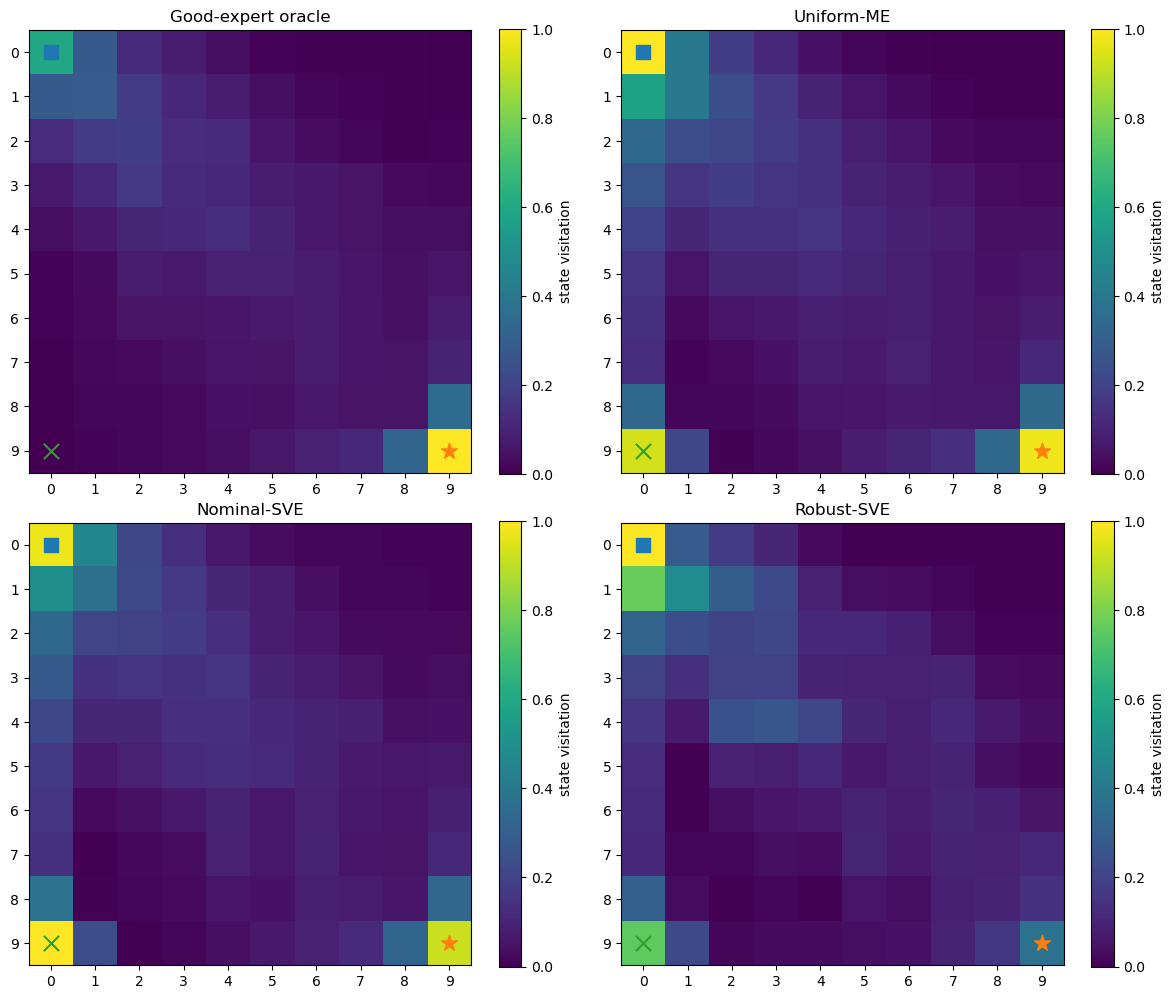

In [11]:
# ============================================================
# Cell 4: Aggregate occupancies and compare target quality
# ============================================================

import pandas as pd

# -----------------------------
# Helper functions
# -----------------------------
def normalize_weights(w):
    total = np.sum(w)
    if total <= 1e-12:
        return np.ones_like(w) / len(w)
    return w / total

def aggregate_occupancy(weights, rho_list):
    weights = normalize_weights(weights)
    return np.sum(weights[:, None] * rho_list, axis=0)

def state_visitation_from_occupancy(rho):
    """
    Convert state-action occupancy into state occupancy.
    """
    state_occ = rho.reshape(n_states, n_actions).sum(axis=1)
    return state_occ.reshape(H, W)

def rkhs_distance(rho1, rho2):
    diff = rho1 - rho2
    val = diff @ K_sa @ diff
    return np.sqrt(max(val, 0.0))

def l1_distance(rho1, rho2):
    return np.sum(np.abs(rho1 - rho2))

# -----------------------------
# Oracle good-expert target
# -----------------------------
good_indices = np.array([e for e, t in enumerate(expert_types) if t == "good"])
noisy_indices = np.array([e for e, t in enumerate(expert_types) if t == "noisy"])
corrupted_indices = np.array([e for e, t in enumerate(expert_types) if t == "corrupted"])

rho_good_oracle = np.mean(rho_hat[good_indices], axis=0)

# -----------------------------
# Different aggregate targets
# -----------------------------
rho_uniform = np.mean(rho_hat, axis=0)

theta_nominal = normalize_weights(alpha_star)
rho_sve = aggregate_occupancy(theta_nominal, rho_hat)

theta_robust = normalize_weights(alpha_robust)
rho_robust_sve = aggregate_occupancy(theta_robust, rho_hat)

targets = {
    "Uniform-ME": rho_uniform,
    "Nominal-SVE": rho_sve,
    "Robust-SVE": rho_robust_sve,
}

# -----------------------------
# Quantitative comparison
# -----------------------------
rows = []

for name, rho_target in targets.items():
    rows.append({
        "Method": name,
        "RKHS error to good experts ↓": rkhs_distance(rho_target, rho_good_oracle),
        "L1 error to good experts ↓": l1_distance(rho_target, rho_good_oracle),
        "Selected experts": np.sum(
            alpha_robust > tau_alpha
        ) if name == "Robust-SVE" else (
            np.sum(alpha_star > tau_alpha) if name == "Nominal-SVE" else E
        )
    })

df_results = pd.DataFrame(rows)
display(df_results)

# -----------------------------
# Print weights
# -----------------------------
print("Nominal SVE weights:")
for e in range(E):
    if theta_nominal[e] > tau_alpha:
        print(f"  Expert {e+1:2d} | {expert_types[e]:9s} | theta = {theta_nominal[e]:.4f}")

print("\nRobust SVE weights:")
for e in range(E):
    if theta_robust[e] > tau_alpha:
        print(f"  Expert {e+1:2d} | {expert_types[e]:9s} | theta = {theta_robust[e]:.4f}")

# -----------------------------
# Plot state-visitation heatmaps
# -----------------------------
heatmaps = {
    "Good-expert oracle": rho_good_oracle,
    "Uniform-ME": rho_uniform,
    "Nominal-SVE": rho_sve,
    "Robust-SVE": rho_robust_sve,
}

plt.figure(figsize=(12, 10))

for i, (name, rho_target) in enumerate(heatmaps.items(), start=1):
    plt.subplot(2, 2, i)
    state_occ = state_visitation_from_occupancy(rho_target)

    plt.imshow(state_occ)
    plt.scatter(start[1], start[0], marker="s", s=100, label="start")
    plt.scatter(goal[1], goal[0], marker="*", s=140, label="goal")
    plt.scatter(bad_goal[1], bad_goal[0], marker="x", s=120, label="bad goal")

    plt.title(name)
    plt.xticks(range(W))
    plt.yticks(range(H))
    plt.colorbar(label="state visitation")

plt.tight_layout()
plt.show()

,Method,Average cost ↓,Std cost,Success rate ↑,Average length ↓
0,Random,14.468174,0.189565,0.000,25.000
1,Good-oracle,13.984121,0.856088,0.496,23.852
2,Uniform-ME,16.959743,5.855308,0.256,24.422
3,Nominal-SVE,17.108162,5.964871,0.246,24.548
4,Robust-SVE,16.853476,5.184604,0.138,24.856


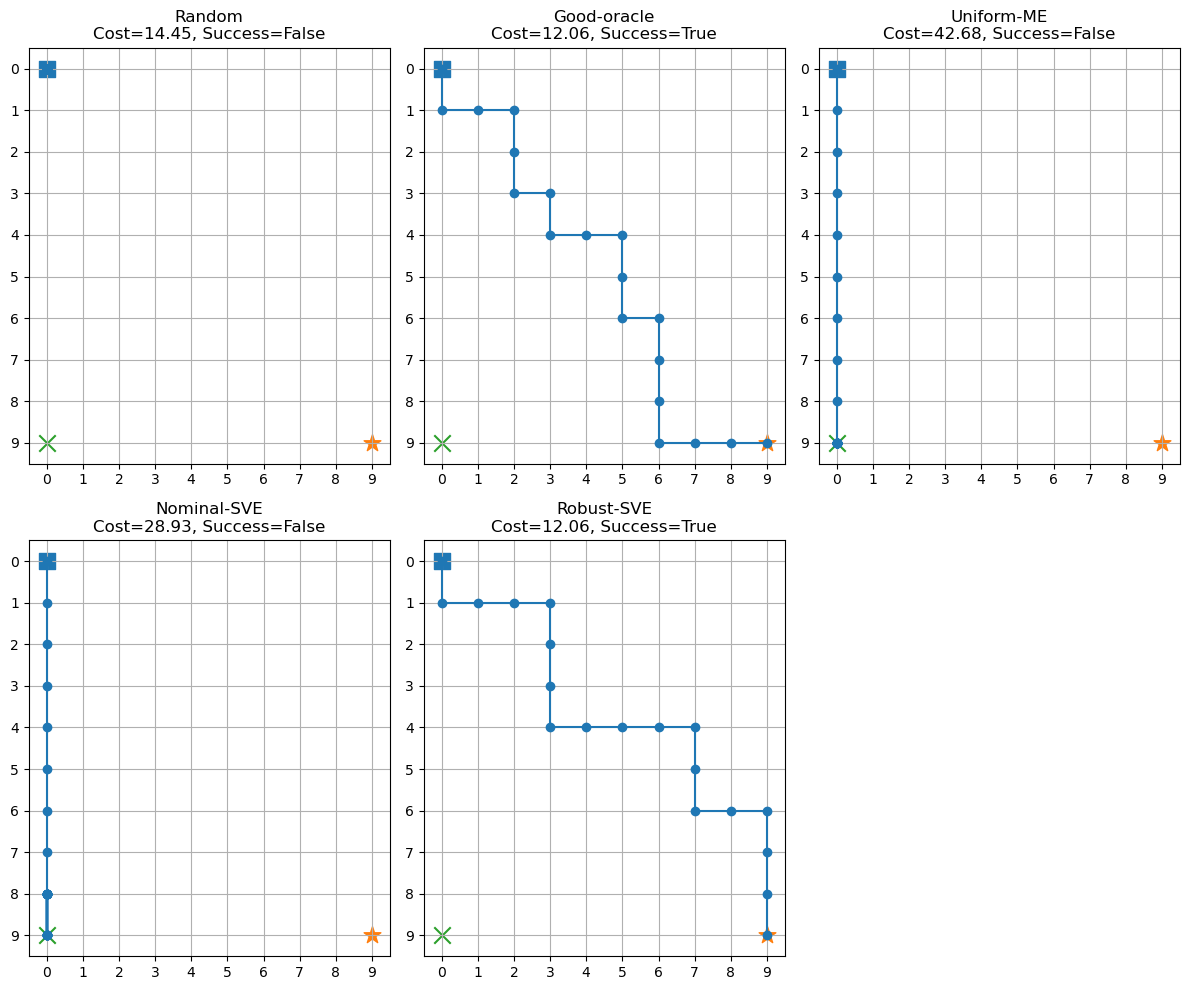

In [12]:
# ============================================================
# Cell 5: Convert aggregate occupancies into policies and evaluate
# ============================================================

# -----------------------------
# Cost function for evaluation
# -----------------------------
def eval_cost(s):
    """
    Simple evaluation cost:
    - reaching the true goal is good
    - reaching the bad goal is bad
    - otherwise each step has unit cost
    """
    if s == goal:
        return 0.0
    elif s == bad_goal:
        return 5.0
    else:
        return 1.0

# -----------------------------
# Convert occupancy into policy
# pi(a|s) = rho(s,a) / sum_a rho(s,a)
# -----------------------------
def policy_from_occupancy(rho, smoothing=1e-3):
    rho_sa = rho.reshape(n_states, n_actions)

    pi = rho_sa + smoothing
    pi = pi / pi.sum(axis=1, keepdims=True)

    return pi

pi_good_oracle = policy_from_occupancy(rho_good_oracle)
pi_uniform = policy_from_occupancy(rho_uniform)
pi_sve = policy_from_occupancy(rho_sve)
pi_robust_sve = policy_from_occupancy(rho_robust_sve)

pi_random = np.ones((n_states, n_actions)) / n_actions

policies = {
    "Random": pi_random,
    "Good-oracle": pi_good_oracle,
    "Uniform-ME": pi_uniform,
    "Nominal-SVE": pi_sve,
    "Robust-SVE": pi_robust_sve,
}

# -----------------------------
# Rollout and evaluation
# -----------------------------
def rollout_policy(pi, max_steps=T, deterministic=False):
    s = start
    traj = []
    total_cost = 0.0
    success = False

    for t in range(max_steps):
        sid = state_id(s)

        if deterministic:
            a = np.argmax(pi[sid])
        else:
            a = np.random.choice(n_actions, p=pi[sid])

        traj.append((s, a))

        total_cost += (gamma ** t) * eval_cost(s)

        if s == goal:
            success = True
            break

        s = step(s, a)

    if s == goal:
        success = True

    return traj, total_cost, success

def evaluate_policy(pi, n_rollouts=300, deterministic=False):
    costs = []
    successes = []
    lengths = []

    for _ in range(n_rollouts):
        traj, cost, success = rollout_policy(
            pi,
            max_steps=T,
            deterministic=deterministic
        )

        costs.append(cost)
        successes.append(float(success))
        lengths.append(len(traj))

    return {
        "Average cost ↓": np.mean(costs),
        "Std cost": np.std(costs),
        "Success rate ↑": np.mean(successes),
        "Average length ↓": np.mean(lengths),
    }

rows = []

for name, pi in policies.items():
    out = evaluate_policy(pi, n_rollouts=500, deterministic=False)
    out["Method"] = name
    rows.append(out)

df_policy_results = pd.DataFrame(rows)
df_policy_results = df_policy_results[
    ["Method", "Average cost ↓", "Std cost", "Success rate ↑", "Average length ↓"]
]

display(df_policy_results)

# -----------------------------
# Plot one trajectory from each policy
# -----------------------------
plt.figure(figsize=(12, 10))

for i, (name, pi) in enumerate(policies.items(), start=1):
    traj, cost, success = rollout_policy(pi, max_steps=T, deterministic=True)

    plt.subplot(2, 3, i)

    xs = [s[1] for s, a in traj]
    ys = [s[0] for s, a in traj]

    plt.plot(xs, ys, marker="o", linewidth=1.5)
    plt.scatter(start[1], start[0], marker="s", s=120, label="start")
    plt.scatter(goal[1], goal[0], marker="*", s=160, label="goal")
    plt.scatter(bad_goal[1], bad_goal[0], marker="x", s=140, label="bad goal")

    plt.xlim(-0.5, W - 0.5)
    plt.ylim(H - 0.5, -0.5)
    plt.xticks(range(W))
    plt.yticks(range(H))
    plt.grid(True)
    plt.title(f"{name}\nCost={cost:.2f}, Success={success}")

plt.tight_layout()
plt.show()

Running corruption level kappa = 0.00
Running corruption level kappa = 0.20
Running corruption level kappa = 0.40
Running corruption level kappa = 0.60
Running corruption level kappa = 0.80
Running corruption level kappa = 1.00


,kappa,Method,Average cost ↓,Success rate ↑,RKHS error to good experts ↓,Selected experts,Corrupted weight mass ↓
0,0.0,Uniform-ME,14.209869,0.376667,0.040062,10,2.000000e-01
1,0.0,Nominal-SVE,14.284933,0.316667,0.048741,6,2.997313e-01
2,0.0,Robust-SVE,14.473297,0.176667,0.142057,1,8.271018e-16
3,0.2,Uniform-ME,14.232626,0.303333,0.061659,10,2.000000e-01
4,0.2,Nominal-SVE,14.367513,0.306667,0.072224,7,1.756684e-01
5,0.2,Robust-SVE,14.401726,0.126667,0.145524,1,2.784889e-15
6,0.4,Uniform-ME,14.479188,0.226667,0.088816,10,2.000000e-01
7,0.4,Nominal-SVE,14.657749,0.263333,0.102634,8,2.265278e-01
8,0.4,Robust-SVE,15.265687,0.036667,0.214042,2,5.811971e-01
9,0.6,Uniform-ME,14.823256,0.276667,0.116790,10,2.000000e-01


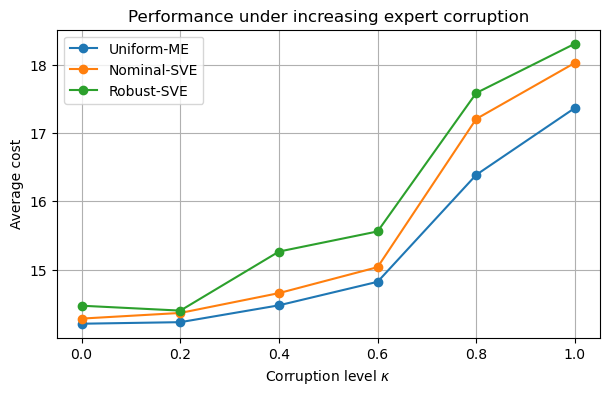

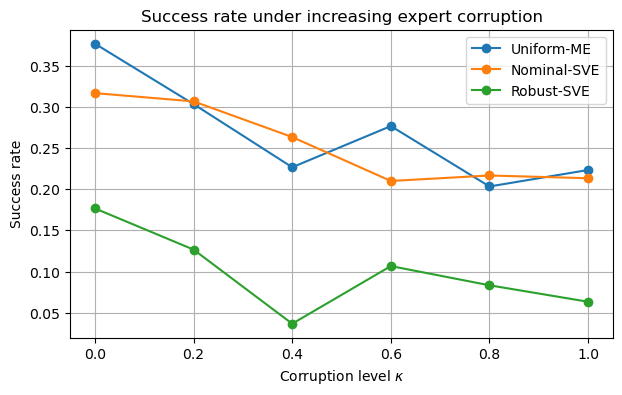

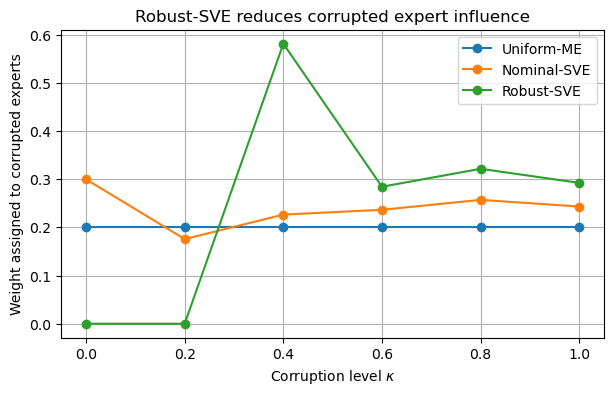

In [13]:
# ============================================================
# Cell 6: Corruption-level sweep
# ============================================================

def generate_trajectory_corruption_sweep(expert_type, kappa=0.0, noise_prob=0.0):
    """
    kappa controls how corrupted the corrupted experts are.

    kappa = 0: corrupted experts behave like good experts.
    kappa = 1: corrupted experts fully move toward the bad goal.
    """
    s = start
    traj = []

    for t in range(T):

        if expert_type == "good":
            a = greedy_action_toward(s, goal)

        elif expert_type == "noisy":
            if np.random.rand() < noise_prob:
                a = np.random.choice(n_actions)
            else:
                a = greedy_action_toward(s, goal)

        elif expert_type == "corrupted":
            if np.random.rand() < kappa:
                a = greedy_action_toward(s, bad_goal)
            else:
                a = greedy_action_toward(s, goal)

        else:
            raise ValueError("Unknown expert type.")

        traj.append((s, a))
        s = step(s, a)

    return traj


def solve_nominal_sve(rho_hat_current, rho_pi_current):
    G = rho_hat_current @ K_sa @ rho_hat_current.T

    g_ep = np.array([
        embedding_inner_product(rho_hat_current[e], rho_pi_current)
        for e in range(E)
    ])

    g_pp = embedding_inner_product(rho_pi_current, rho_pi_current)

    def obj(x):
        alpha = x[:E]
        alpha_pi = x[E]

        norm_sq = (
            alpha @ G @ alpha
            - 2 * alpha_pi * (alpha @ g_ep)
            + alpha_pi ** 2 * g_pp
        )

        value = np.sum(alpha) + alpha_pi - 0.5 * norm_sq
        return -value

    bounds = [(0, C)] * E + [(0, C_pi)]
    x0 = np.ones(E + 1) * 0.1

    res = minimize(obj, x0, method="L-BFGS-B", bounds=bounds)

    return res.x[:E], res.x[E], G, g_ep, g_pp


def solve_robust_sve(rho_hat_current, rho_pi_current, eps_current):
    G = rho_hat_current @ K_sa @ rho_hat_current.T

    g_ep = np.array([
        embedding_inner_product(rho_hat_current[e], rho_pi_current)
        for e in range(E)
    ])

    g_pp = embedding_inner_product(rho_pi_current, rho_pi_current)

    def obj(x):
        alpha = x[:E]
        beta = x[E]

        norm_sq = (
            alpha @ G @ alpha
            - 2 * beta * (alpha @ g_ep)
            + beta ** 2 * g_pp
        )

        norm_val = np.sqrt(max(norm_sq, 0.0))
        shrinkage = alpha @ eps_current + beta * epsilon_pi
        robust_margin = max(norm_val - shrinkage, 0.0)

        value = np.sum(alpha) + beta - 0.5 * robust_margin ** 2
        return -value

    bounds = [(0, C_E)] * E + [(0, C_pi)]

    constraints = [
        {
            "type": "eq",
            "fun": lambda x: x[E] - np.sum(x[:E])
        }
    ]

    x0 = np.zeros(E + 1)
    x0[:E] = 0.05 / E
    x0[E] = np.sum(x0[:E])

    res = minimize(
        obj,
        x0,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 1000, "ftol": 1e-9}
    )

    return res.x[:E], res.x[E]


def run_one_corruption_level(kappa, n_eval_rollouts=300):
    # -----------------------------
    # Generate experts
    # -----------------------------
    expert_trajectories_current = []

    for e in range(E):
        etype = expert_types[e]

        demos = [
            generate_trajectory_corruption_sweep(
                etype,
                kappa=kappa,
                noise_prob=0.25
            )
            for _ in range(N_per_expert)
        ]

        expert_trajectories_current.append(demos)

    rho_hat_current = np.array([
        empirical_occupancy(expert_trajectories_current[e])
        for e in range(E)
    ])

    # -----------------------------
    # Fixed random learner occupancy
    # -----------------------------
    learner_trajectories_current = [
        generate_random_policy_trajectory()
        for _ in range(N_pi)
    ]

    rho_pi_current = empirical_occupancy(learner_trajectories_current)

    # -----------------------------
    # Oracle good target
    # -----------------------------
    rho_good_current = np.mean(rho_hat_current[good_indices], axis=0)

    # -----------------------------
    # Nominal SVE
    # -----------------------------
    alpha_nom, alpha_pi_nom, _, _, _ = solve_nominal_sve(
        rho_hat_current,
        rho_pi_current
    )

    theta_nom = normalize_weights(alpha_nom)
    rho_nominal_sve_current = aggregate_occupancy(theta_nom, rho_hat_current)

    # -----------------------------
    # Robust SVE
    # -----------------------------
    eps_current = np.zeros(E)

    for e, etype in enumerate(expert_types):
        if etype == "good":
            eps_current[e] = 0.02
        elif etype == "noisy":
            eps_current[e] = 0.08
        elif etype == "corrupted":
            eps_current[e] = 0.02 + 0.25 * kappa

    alpha_rob, beta_rob = solve_robust_sve(
        rho_hat_current,
        rho_pi_current,
        eps_current
    )

    theta_rob = normalize_weights(alpha_rob)
    rho_robust_sve_current = aggregate_occupancy(theta_rob, rho_hat_current)

    # -----------------------------
    # Uniform baseline
    # -----------------------------
    rho_uniform_current = np.mean(rho_hat_current, axis=0)

    methods = {
        "Uniform-ME": rho_uniform_current,
        "Nominal-SVE": rho_nominal_sve_current,
        "Robust-SVE": rho_robust_sve_current,
    }

    rows = []

    for name, rho_target in methods.items():
        pi_target = policy_from_occupancy(rho_target)

        eval_out = evaluate_policy(
            pi_target,
            n_rollouts=n_eval_rollouts,
            deterministic=False
        )

        if name == "Uniform-ME":
            selected = E
            corrupted_weight = 2 / E

        elif name == "Nominal-SVE":
            selected = np.sum(alpha_nom > tau_alpha)
            corrupted_weight = np.sum(theta_nom[corrupted_indices])

        elif name == "Robust-SVE":
            selected = np.sum(alpha_rob > tau_alpha)
            corrupted_weight = np.sum(theta_rob[corrupted_indices])

        rows.append({
            "kappa": kappa,
            "Method": name,
            "Average cost ↓": eval_out["Average cost ↓"],
            "Success rate ↑": eval_out["Success rate ↑"],
            "RKHS error to good experts ↓": rkhs_distance(rho_target, rho_good_current),
            "Selected experts": selected,
            "Corrupted weight mass ↓": corrupted_weight,
        })

    return rows


# -----------------------------
# Run sweep
# -----------------------------
kappa_grid = np.linspace(0.0, 1.0, 6)

all_rows = []

for kappa in kappa_grid:
    print(f"Running corruption level kappa = {kappa:.2f}")
    rows = run_one_corruption_level(kappa, n_eval_rollouts=300)
    all_rows.extend(rows)

df_sweep = pd.DataFrame(all_rows)
display(df_sweep)

# -----------------------------
# Plot average cost vs corruption
# -----------------------------
plt.figure(figsize=(7, 4))

for method in df_sweep["Method"].unique():
    df_m = df_sweep[df_sweep["Method"] == method]
    plt.plot(
        df_m["kappa"],
        df_m["Average cost ↓"],
        marker="o",
        label=method
    )

plt.xlabel(r"Corruption level $\kappa$")
plt.ylabel("Average cost")
plt.title("Performance under increasing expert corruption")
plt.grid(True)
plt.legend()
plt.show()

# -----------------------------
# Plot success rate vs corruption
# -----------------------------
plt.figure(figsize=(7, 4))

for method in df_sweep["Method"].unique():
    df_m = df_sweep[df_sweep["Method"] == method]
    plt.plot(
        df_m["kappa"],
        df_m["Success rate ↑"],
        marker="o",
        label=method
    )

plt.xlabel(r"Corruption level $\kappa$")
plt.ylabel("Success rate")
plt.title("Success rate under increasing expert corruption")
plt.grid(True)
plt.legend()
plt.show()

# -----------------------------
# Plot corrupted expert weight mass
# -----------------------------
plt.figure(figsize=(7, 4))

for method in ["Uniform-ME", "Nominal-SVE", "Robust-SVE"]:
    df_m = df_sweep[df_sweep["Method"] == method]
    plt.plot(
        df_m["kappa"],
        df_m["Corrupted weight mass ↓"],
        marker="o",
        label=method
    )

plt.xlabel(r"Corruption level $\kappa$")
plt.ylabel("Weight assigned to corrupted experts")
plt.title("Robust-SVE reduces corrupted expert influence")
plt.grid(True)
plt.legend()
plt.show()

Seed 1/100
Seed 2/100
Seed 3/100
Seed 4/100
Seed 5/100
Seed 6/100
Seed 7/100
Seed 8/100
Seed 9/100
Seed 10/100
Seed 11/100
Seed 12/100
Seed 13/100
Seed 14/100
Seed 15/100
Seed 16/100
Seed 17/100
Seed 18/100
Seed 19/100
Seed 20/100
Seed 21/100
Seed 22/100
Seed 23/100
Seed 24/100
Seed 25/100
Seed 26/100
Seed 27/100
Seed 28/100
Seed 29/100
Seed 30/100
Seed 31/100
Seed 32/100
Seed 33/100
Seed 34/100
Seed 35/100
Seed 36/100
Seed 37/100
Seed 38/100
Seed 39/100
Seed 40/100
Seed 41/100
Seed 42/100
Seed 43/100
Seed 44/100
Seed 45/100
Seed 46/100
Seed 47/100
Seed 48/100
Seed 49/100
Seed 50/100
Seed 51/100
Seed 52/100
Seed 53/100
Seed 54/100
Seed 55/100
Seed 56/100
Seed 57/100
Seed 58/100
Seed 59/100
Seed 60/100
Seed 61/100
Seed 62/100
Seed 63/100
Seed 64/100
Seed 65/100
Seed 66/100
Seed 67/100
Seed 68/100
Seed 69/100
Seed 70/100
Seed 71/100
Seed 72/100
Seed 73/100
Seed 74/100
Seed 75/100
Seed 76/100
Seed 77/100
Seed 78/100
Seed 79/100
Seed 80/100
Seed 81/100
Seed 82/100
Seed 83/100
Seed 84/100
S

kappa       Method Average cost ↓           Success rate ↑            \
                                mean       std           mean       std   
0    0.0  Nominal-SVE      14.218220  0.080160        0.35270  0.046474   
1    0.0   Robust-SVE      14.388540  0.066099        0.16910  0.037155   
2    0.0   Uniform-ME      14.137417  0.062463        0.39810  0.034850   
3    0.2  Nominal-SVE      14.284437  0.088375        0.31975  0.045861   
4    0.2   Robust-SVE      14.402874  0.062305        0.15785  0.041653   
5    0.2   Uniform-ME      14.262339  0.080983        0.33220  0.038856   
6    0.4  Nominal-SVE      14.585186  0.160841        0.26565  0.037360   
7    0.4   Robust-SVE      14.798909  0.178225        0.10560  0.030370   
8    0.4   Uniform-ME      14.517813  0.119588        0.26750  0.037020   
9    0.6  Nominal-SVE      15.457271  0.255586        0.23470  0.037537   
10   0.6   Robust-SVE      15.845949  0.476497        0.07630  0.029760   
11   0.6   Uniform-ME      15.140025  0.222898        0.24985  0.034644   
12   0.8  Nominal-SVE      16.602002  0.393464        0.24200  0.040314   
13   0.8   Robust-SVE      17.198214  0.659793        0.08350  0.028591   
14   0.8   Uniform-ME      16.042840  0.347780        0.25200  0.030617   
15   1.0  Nominal-SVE      17.502841  0.448248        0.24185  0.037677   
16   1.0   Robust-SVE      18.453537  0.807236        0.08885  0.023027   
17   1.0   Uniform-ME      17.005114  0.416000        0.24840  0.035075   

   RKHS error to good experts ↓           Corrupted weight mass ↓  \
                           mean       std                    mean   
0                      0.050031  0.009840            1.660326e-01   
1                      0.132460  0.015135            7.953179e-15   
2                      0.037366  0.004248            2.000000e-01   
3                      0.062682  0.012250            1.463656e-01   
4                      0.137440  0.017326            1.799159e-03   
5                      0.060074  0.007672            2.000000e-01   
6                      0.093255  0.013460            2.183946e-01   
7                      0.171204  0.016878            3.209848e-01   
8                      0.089968  0.007562            2.000000e-01   
9                      0.127108  0.012042            2.491871e-01   
10                     0.211436  0.020722            3.471653e-01   
11                     0.114017  0.007234            2.000000e-01   
12                     0.145723  0.009077            2.487211e-01   
13                     0.219864  0.015976            3.125529e-01   
14                     0.128375  0.005785            2.000000e-01   
15                     0.152765  0.008305            2.303568e-01   
16                     0.223945  0.016882            2.849864e-01   
17                     0.142449  0.006369            2.000000e-01   

                 Selected experts            
             std             mean       std  
0   1.166750e-01             6.74  0.824131  
1   1.067566e-14             1.40  0.531816  
2   0.000000e+00            10.00  0.000000  
3   8.930120e-02             6.80  0.651339  
4   1.799159e-02             1.37  0.505625  
5   0.000000e+00            10.00  0.000000  
6   4.177308e-02             7.18  0.701801  
7   1.186140e-01             2.24  0.429235  
8   0.000000e+00            10.00  0.000000  
9   2.847999e-02             7.43  0.728288  
10  8.272991e-02             2.21  0.409360  
11  0.000000e+00            10.00  0.000000  
12  1.464825e-02             7.55  0.833333  
13  5.264381e-02             2.18  0.386123  
14  0.000000e+00            10.00  0.000000  
15  1.237588e-02             7.53  0.673525  
16  3.745048e-02             2.45  0.575159  
17  0.000000e+00            10.00  0.000000

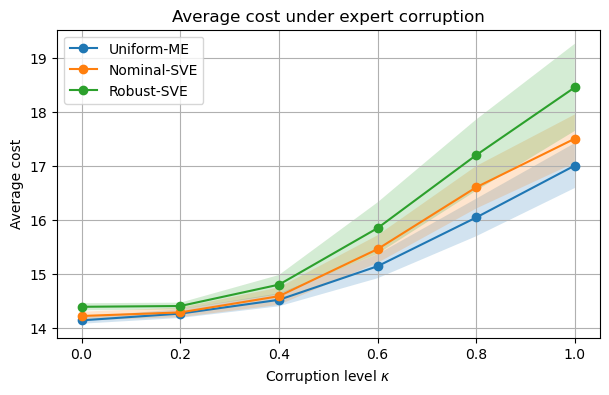

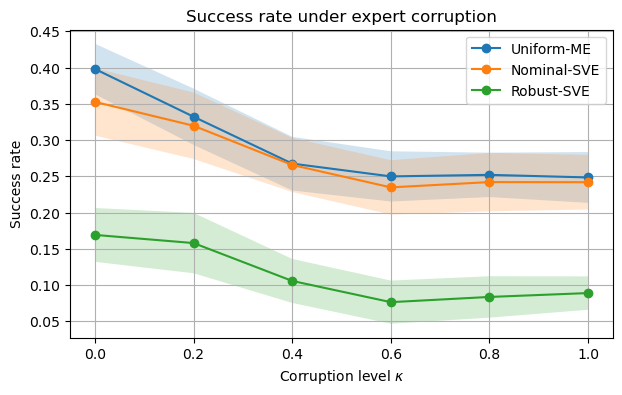

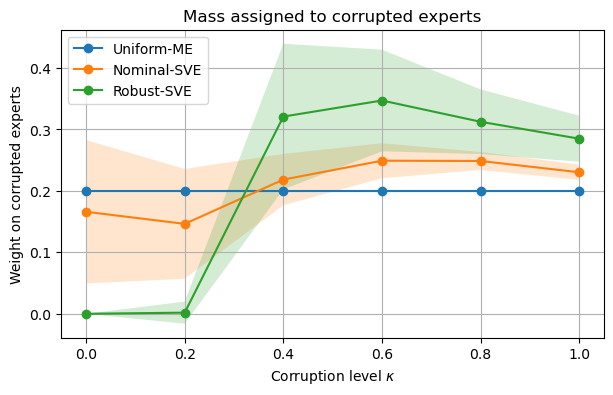

In [14]:
# ============================================================
# Cell 7: Repeat experiments over random seeds for mean/std
# ============================================================

n_seeds = 100
kappa_grid = np.linspace(0.0, 1.0, 6)

all_seed_rows = []

for seed in range(n_seeds):
    print(f"Seed {seed+1}/{n_seeds}")
    np.random.seed(seed)

    for kappa in kappa_grid:
        rows = run_one_corruption_level(kappa, n_eval_rollouts=200)

        for row in rows:
            row["seed"] = seed
            all_seed_rows.append(row)

df_seed = pd.DataFrame(all_seed_rows)

summary = (
    df_seed
    .groupby(["kappa", "Method"])
    .agg({
        "Average cost ↓": ["mean", "std"],
        "Success rate ↑": ["mean", "std"],
        "RKHS error to good experts ↓": ["mean", "std"],
        "Corrupted weight mass ↓": ["mean", "std"],
        "Selected experts": ["mean", "std"],
    })
    .reset_index()
)

display(summary)

# -----------------------------
# Plot mean ± std: average cost
# -----------------------------
plt.figure(figsize=(7, 4))

for method in df_seed["Method"].unique():
    df_m = df_seed[df_seed["Method"] == method]

    mean = df_m.groupby("kappa")["Average cost ↓"].mean()
    std = df_m.groupby("kappa")["Average cost ↓"].std()

    plt.plot(mean.index, mean.values, marker="o", label=method)
    plt.fill_between(mean.index, mean.values - std.values, mean.values + std.values, alpha=0.2)

plt.xlabel(r"Corruption level $\kappa$")
plt.ylabel("Average cost")
plt.title("Average cost under expert corruption")
plt.grid(True)
plt.legend()
plt.show()

# -----------------------------
# Plot mean ± std: success rate
# -----------------------------
plt.figure(figsize=(7, 4))

for method in df_seed["Method"].unique():
    df_m = df_seed[df_seed["Method"] == method]

    mean = df_m.groupby("kappa")["Success rate ↑"].mean()
    std = df_m.groupby("kappa")["Success rate ↑"].std()

    plt.plot(mean.index, mean.values, marker="o", label=method)
    plt.fill_between(mean.index, mean.values - std.values, mean.values + std.values, alpha=0.2)

plt.xlabel(r"Corruption level $\kappa$")
plt.ylabel("Success rate")
plt.title("Success rate under expert corruption")
plt.grid(True)
plt.legend()
plt.show()

# -----------------------------
# Plot mean ± std: corrupted expert mass
# -----------------------------
plt.figure(figsize=(7, 4))

for method in df_seed["Method"].unique():
    df_m = df_seed[df_seed["Method"] == method]

    mean = df_m.groupby("kappa")["Corrupted weight mass ↓"].mean()
    std = df_m.groupby("kappa")["Corrupted weight mass ↓"].std()

    plt.plot(mean.index, mean.values, marker="o", label=method)
    plt.fill_between(mean.index, mean.values - std.values, mean.values + std.values, alpha=0.2)

plt.xlabel(r"Corruption level $\kappa$")
plt.ylabel("Weight on corrupted experts")
plt.title("Mass assigned to corrupted experts")
plt.grid(True)
plt.legend()
plt.show()